In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

df = pd.read_csv('yulu.csv')

In [4]:
print(df.shape)

(10886, 12)


In [5]:
display(df.head())

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,01-01-2011 00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,01-01-2011 01:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,01-01-2011 02:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,01-01-2011 03:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,01-01-2011 04:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


In [8]:
# Check for missing values
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
casual        0
registered    0
count         0
dtype: int64


In [10]:
#Check for duplicate rows
print("\n Number of duplicate rows:", df.duplicated().sum())


 Number of duplicate rows: 0


In [12]:
# Check the current format of datetime values
print(df['datetime'].head(10))


0    01-01-2011 00:00
1    01-01-2011 01:00
2    01-01-2011 02:00
3    01-01-2011 03:00
4    01-01-2011 04:00
5    01-01-2011 05:00
6    01-01-2011 06:00
7    01-01-2011 07:00
8    01-01-2011 08:00
9    01-01-2011 09:00
Name: datetime, dtype: object


In [13]:
# Check the current datatype
print("\nDatatype:", df['datetime'].dtype)


Datatype: object


In [15]:
# Convert datetime column to datetime format
df['datetime'] = pd.to_datetime(
    df['datetime'],
    format='%d-%m-%Y %H:%M'
)

In [16]:
# Convert categorical variables to category datatype
categorical_cols = ['season', 'holiday', 'workingday', 'weather']

for col in categorical_cols:
    df[col] = df[col].astype('category')


In [17]:
# Check updated data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   datetime    10886 non-null  datetime64[ns]
 1   season      10886 non-null  category      
 2   holiday     10886 non-null  category      
 3   workingday  10886 non-null  category      
 4   weather     10886 non-null  category      
 5   temp        10886 non-null  float64       
 6   atemp       10886 non-null  float64       
 7   humidity    10886 non-null  int64         
 8   windspeed   10886 non-null  float64       
 9   casual      10886 non-null  int64         
 10  registered  10886 non-null  int64         
 11  count       10886 non-null  int64         
dtypes: category(4), datetime64[ns](1), float64(3), int64(4)
memory usage: 723.7 KB


In [18]:
# Generate statistical summary for numerical variables
df.describe().T

,count,mean,min,25%,50%,75%,max,std
datetime,10886,2011-12-27 05:56:22.399411968,2011-01-01 00:00:00,2011-07-02 07:15:00,2012-01-01 20:30:00,2012-07-01 12:45:00,2012-12-19 23:00:00,NaN
temp,10886.0,20.23086,0.82,13.94,20.5,26.24,41.0,7.79159
atemp,10886.0,23.655084,0.76,16.665,24.24,31.06,45.455,8.474601
humidity,10886.0,61.88646,0.0,47.0,62.0,77.0,100.0,19.245033
windspeed,10886.0,12.799395,0.0,7.0015,12.998,16.9979,56.9969,8.164537
casual,10886.0,36.021955,0.0,4.0,17.0,49.0,367.0,49.960477
registered,10886.0,155.552177,0.0,36.0,118.0,222.0,886.0,151.039033
count,10886.0,191.574132,1.0,42.0,145.0,284.0,977.0,181.144454


In [19]:
# Calculate the range of numerical variables
numerical_cols = df.select_dtypes(include='number').columns

range_values = df[numerical_cols].max() - df[numerical_cols].min()

print("Range of numerical variables:")
display(range_values.sort_values(ascending=False))

Range of numerical variables:


count         976.0000
registered    886.0000
casual        367.0000
humidity      100.0000
windspeed      56.9969
atemp          44.6950
temp           40.1800
dtype: float64

In [20]:
# Detect potential outliers using the IQR method

Q1 = df[numerical_cols].quantile(0.25)
Q3 = df[numerical_cols].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_count = ((df[numerical_cols] < lower_bound) |
                 (df[numerical_cols] > upper_bound)).sum()

print("Potential outliers in each numerical variable:")
display(outlier_count)

Potential outliers in each numerical variable:


temp            0
atemp           0
humidity       22
windspeed     227
casual        749
registered    423
count         300
dtype: int64

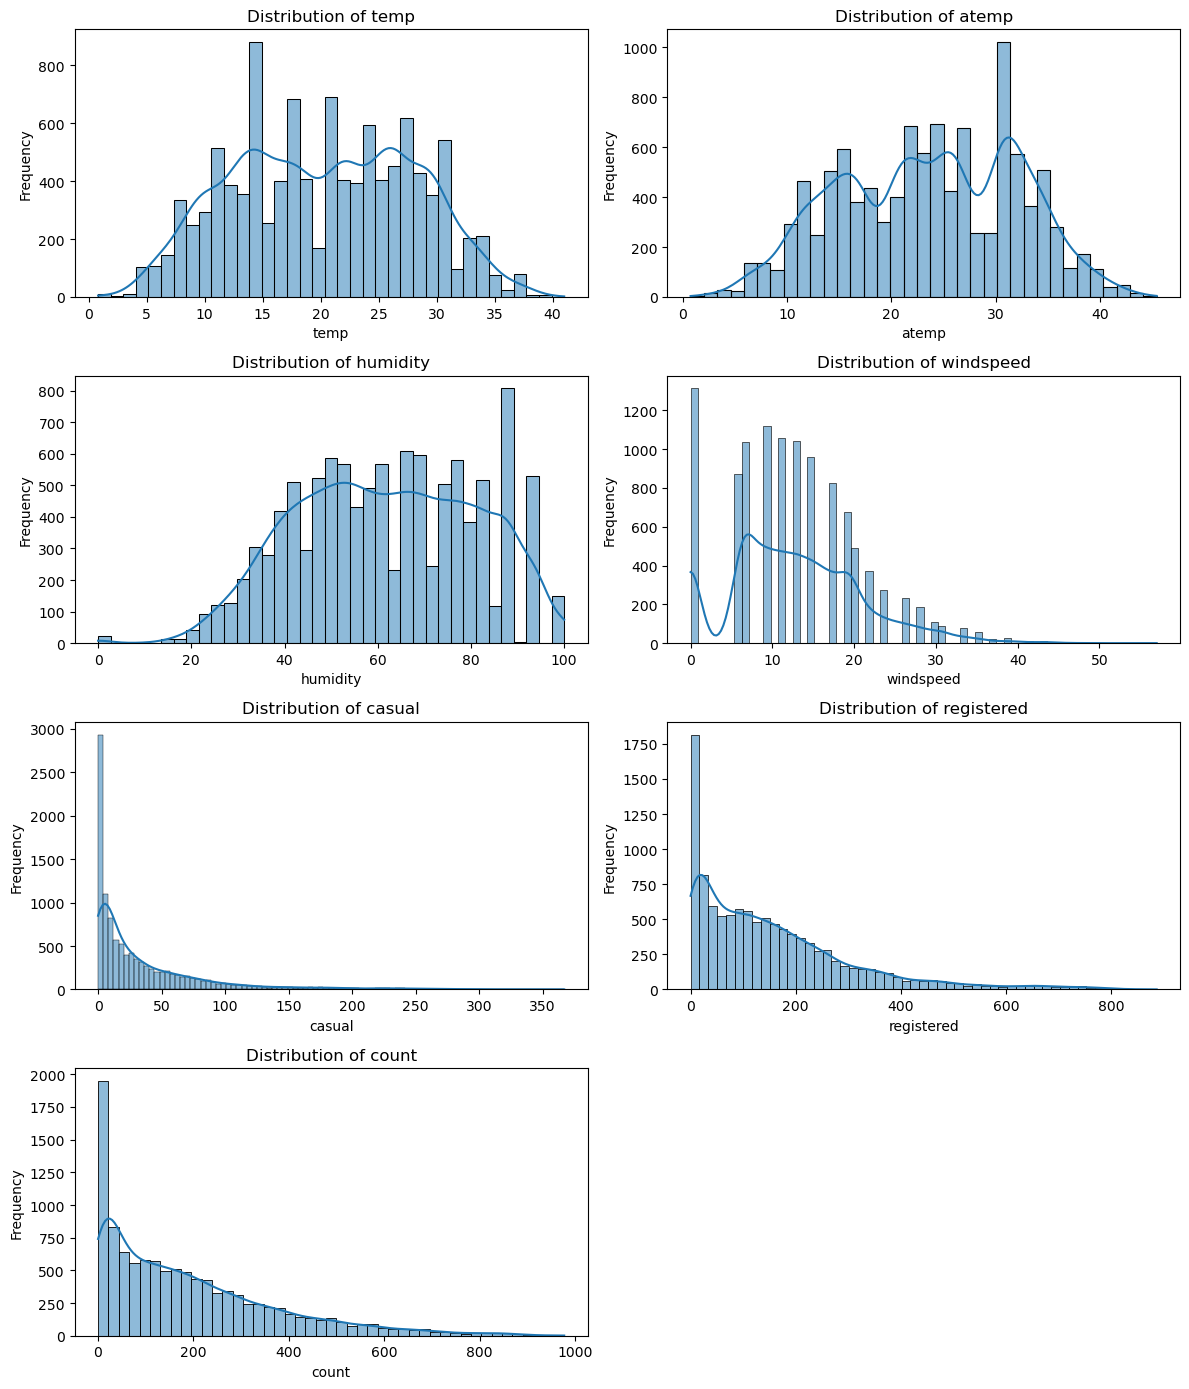

In [23]:
# Distribution plots for continuous variables

continuous_cols = [
    'temp', 'atemp', 'humidity', 'windspeed',
    'casual', 'registered', 'count'
]

fig, axes = plt.subplots(4, 2, figsize=(12, 14))
axes = axes.flatten()

for i, col in enumerate(continuous_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

# Remove unused subplot
axes[-1].remove()

plt.tight_layout()
plt.show()

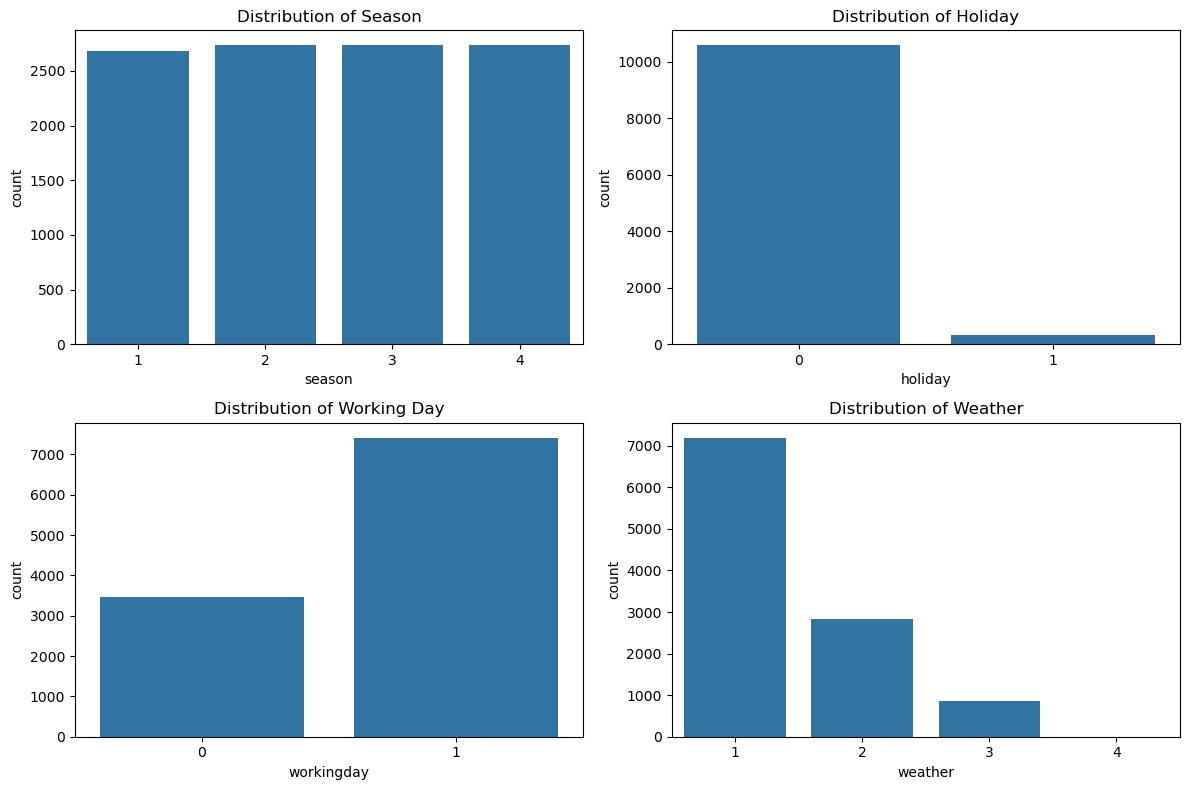

In [24]:
# Count plots for categorical variables

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.countplot(data=df, x='season', ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Season')

sns.countplot(data=df, x='holiday', ax=axes[0, 1])
axes[0, 1].set_title('Distribution of Holiday')

sns.countplot(data=df, x='workingday', ax=axes[1, 0])
axes[1, 0].set_title('Distribution of Working Day')

sns.countplot(data=df, x='weather', ax=axes[1, 1])
axes[1, 1].set_title('Distribution of Weather')

plt.tight_layout()
plt.show()

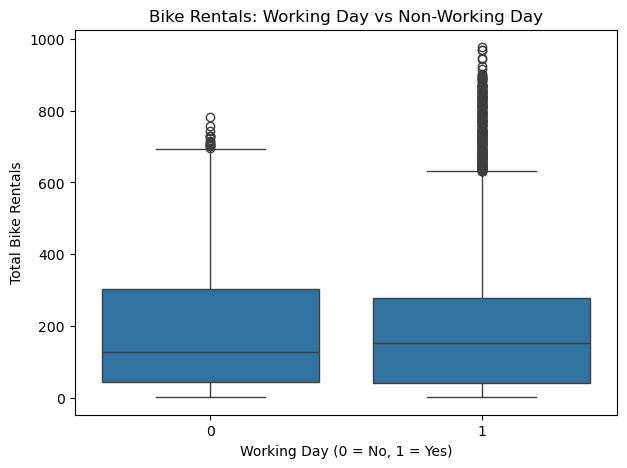

In [25]:
# Working Day vs Total Bike Rentals

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='workingday',
    y='count'
)

plt.title('Bike Rentals: Working Day vs Non-Working Day')
plt.xlabel('Working Day (0 = No, 1 = Yes)')
plt.ylabel('Total Bike Rentals')

plt.show()

In [26]:
# Average number of rentals by working day

df.groupby('workingday', observed=True)['count'].mean()

workingday
0    188.506621
1    193.011873
Name: count, dtype: float64

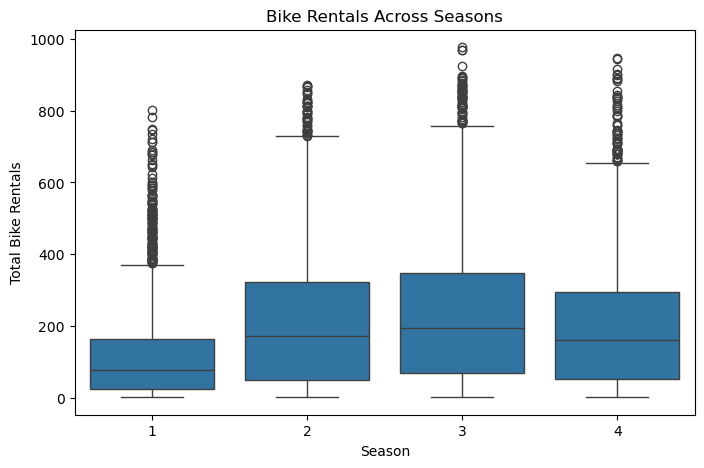

In [27]:
# Season vs Total Bike Rentals

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='season',
    y='count'
)

plt.title('Bike Rentals Across Seasons')
plt.xlabel('Season')
plt.ylabel('Total Bike Rentals')

plt.show()

In [28]:
# Average rentals by weather condition

df.groupby('weather', observed=True)['count'].mean()

weather
1    205.236791
2    178.955540
3    118.846333
4    164.000000
Name: count, dtype: float64

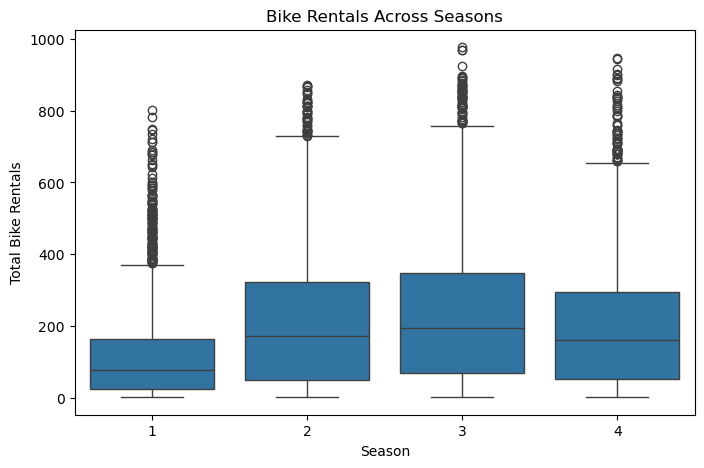

In [29]:
# Season vs Total Bike Rentals

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='season',
    y='count'
)

plt.title('Bike Rentals Across Seasons')
plt.xlabel('Season')
plt.ylabel('Total Bike Rentals')

plt.show()

In [30]:
# Average rentals by weather condition

df.groupby('weather', observed=True)['count'].mean()

weather
1    205.236791
2    178.955540
3    118.846333
4    164.000000
Name: count, dtype: float64

In [31]:
# Separate rental counts into two groups

workingday_0 = df[df['workingday'] == 0]['count']
workingday_1 = df[df['workingday'] == 1]['count']

# Display sample sizes and means

print("Non-working days:")
print("Sample size:", len(workingday_0))
print("Mean:", workingday_0.mean())

print("\nWorking days:")
print("Sample size:", len(workingday_1))
print("Mean:", workingday_1.mean())

Non-working days:
Sample size: 3474
Mean: 188.50662061024755

Working days:
Sample size: 7412
Mean: 193.01187263896384


In [32]:
# Levene's test for equality of variances

levene_stat, levene_p = stats.levene(
    workingday_0,
    workingday_1
)

print("Levene Test Statistic:", levene_stat)
print("Levene Test p-value:", levene_p)

Levene Test Statistic: 0.004972848886504472
Levene Test p-value: 0.9437823280916695


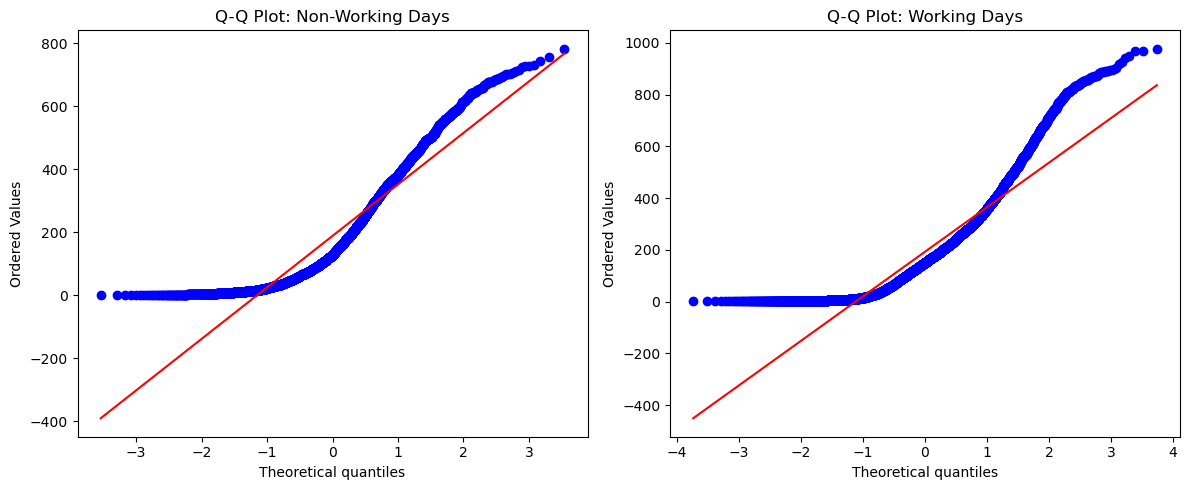

In [33]:
# Q-Q plots for both groups

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

stats.probplot(workingday_0, dist="norm", plot=axes[0])
axes[0].set_title("Q-Q Plot: Non-Working Days")

stats.probplot(workingday_1, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot: Working Days")

plt.tight_layout()
plt.show()

In [34]:
# Independent two-sample t-test

t_stat, p_value = stats.ttest_ind(
    workingday_0,
    workingday_1,
    equal_var=True
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -1.2096277376026694
P-value: 0.22644804226361348


In [35]:
# Calculate average rentals for each season

season_mean = df.groupby('season', observed=True)['count'].mean()

print("Average bike rentals by season:")
display(season_mean)

Average bike rentals by season:


season
1    116.343261
2    215.251372
3    234.417124
4    198.988296
Name: count, dtype: float64

In [36]:
# Create groups for each season

season_groups = [
    group['count'].values
    for _, group in df.groupby('season', observed=True)
]

# Levene's test

levene_stat, levene_p = stats.levene(*season_groups)

print("Levene Test Statistic:", levene_stat)
print("Levene Test p-value:", levene_p)

Levene Test Statistic: 187.7706624026276
Levene Test p-value: 1.0147116860043298e-118


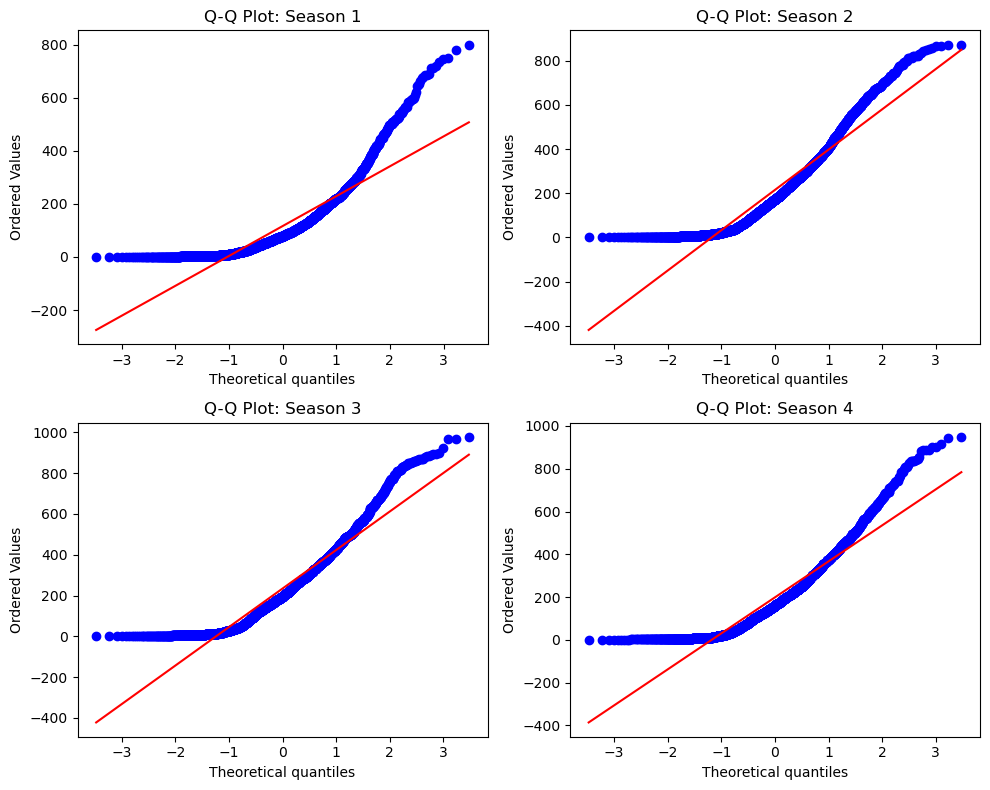

In [37]:
# Q-Q plots for rental count across seasons

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i, (season, group) in enumerate(
    df.groupby('season', observed=True)
):
    stats.probplot(
        group['count'],
        dist="norm",
        plot=axes[i]
    )
    axes[i].set_title(f'Q-Q Plot: Season {season}')

plt.tight_layout()
plt.show()

In [38]:
# Perform one-way ANOVA

anova_stat, anova_p = stats.f_oneway(*season_groups)

print("ANOVA F-statistic:", anova_stat)
print("ANOVA p-value:", anova_p)

ANOVA F-statistic: 236.94671081032106
ANOVA p-value: 6.164843386499654e-149


In [39]:
# Average rentals by weather condition

weather_mean = df.groupby('weather', observed=True)['count'].mean()

print("Average bike rentals by weather:")
display(weather_mean)

Average bike rentals by weather:


weather
1    205.236791
2    178.955540
3    118.846333
4    164.000000
Name: count, dtype: float64

In [40]:
# Create groups for each weather condition

weather_groups = [
    group['count'].values
    for _, group in df.groupby('weather', observed=True)
]

# Levene's test

levene_stat, levene_p = stats.levene(*weather_groups)

print("Levene Test Statistic:", levene_stat)
print("Levene Test p-value:", levene_p)

Levene Test Statistic: 54.85106195954556
Levene Test p-value: 3.504937946833238e-35


C:\Users\ArpiT KapooR\anaconda3\Lib\site-packages\scipy\stats\_morestats.py:640: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  slope, intercept, r, prob, _ = _stats_py.linregress(osm, osr)


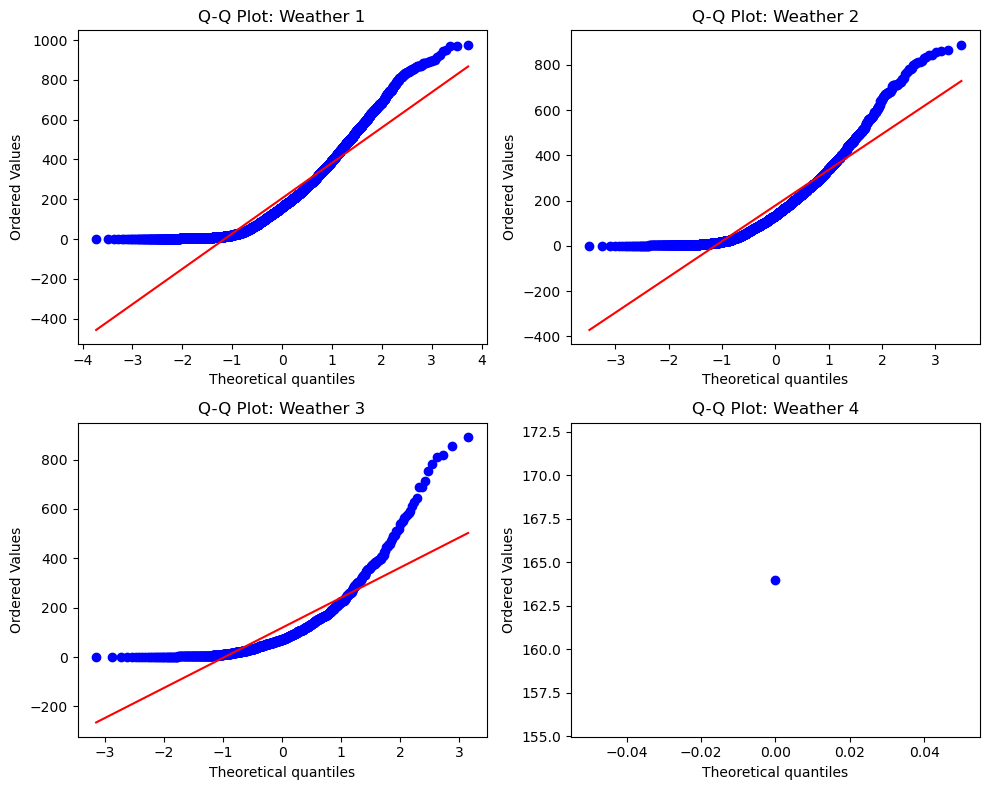

In [41]:
# Q-Q plots for rental count across weather conditions

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i, (weather, group) in enumerate(
    df.groupby('weather', observed=True)
):
    stats.probplot(
        group['count'],
        dist="norm",
        plot=axes[i]
    )
    axes[i].set_title(f'Q-Q Plot: Weather {weather}')

plt.tight_layout()
plt.show()

In [42]:
# Perform one-way ANOVA

anova_weather_stat, anova_weather_p = stats.f_oneway(
    *weather_groups
)

print("ANOVA F-statistic:", anova_weather_stat)
print("ANOVA p-value:", anova_weather_p)

ANOVA F-statistic: 65.53024112793265
ANOVA p-value: 5.482069475935669e-42


In [43]:
# Create contingency table between season and weather

contingency_table = pd.crosstab(
    df['season'],
    df['weather']
)

print("Contingency Table:")
display(contingency_table)

Contingency Table:


weather,1,2,3,4
season,,,,
1,1759,715,211,1
2,1801,708,224,0
3,1930,604,199,0
4,1702,807,225,0


In [44]:
# Perform Chi-Square test of independence

chi2_stat, chi2_p, degrees_freedom, expected = stats.chi2_contingency(
    contingency_table
)

print("Chi-Square Statistic:", chi2_stat)
print("P-value:", chi2_p)
print("Degrees of Freedom:", degrees_freedom)

Chi-Square Statistic: 49.158655596893624
P-value: 1.549925073686492e-07
Degrees of Freedom: 9


In [45]:
# Display expected frequencies

expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("Expected Frequencies:")
display(expected_df)

Expected Frequencies:


weather,1,2,3,4
season,,,,
1,1774.546390,699.258130,211.948742,0.246739
2,1805.597648,711.493845,215.657450,0.251056
3,1805.597648,711.493845,215.657450,0.251056
4,1806.258313,711.754180,215.736359,0.251148


In [46]:
# Check expected frequencies below 5

print(
    "Number of expected frequencies below 5:",
    (expected < 5).sum()
)

Number of expected frequencies below 5: 4


In [ ]:
### Key Insights from Exploratory Data Analysis

1. The dataset contains 10,886 observations and 12 variables, with no missing values or duplicate records.

2. The rental count is right-skewed, with the mean number of rentals higher than the median. The variables casual and registered also show considerable right skewness.

3. Rental demand varies considerably across seasons. Spring has the lowest average rental count, while fall has the highest.

4. Rental demand also varies across weather conditions. Clear weather has the highest average rental demand, while light rain/snow conditions have substantially lower demand.

5. Working days and non-working days have very similar average rental counts, suggesting that working day may have a relatively limited effect on overall rental demand.

6. Weather category 4 is extremely rare, containing only one observation. Therefore, conclusions involving this category should be interpreted cautiously.

In [ ]:
### Final Business Conclusion

The analysis indicates that season and weather conditions are important factors associated with bicycle rental demand, whereas working day does not have a statistically significant effect on the average number of rentals.

Rental demand is highest during favourable weather conditions and varies considerably across seasons, with fall showing the highest average demand and spring the lowest. These findings suggest that the company should consider seasonal demand patterns and weather conditions when planning bicycle availability and operational capacity.

The Chi-square analysis also indicates a significant association between season and weather conditions, suggesting that these factors are not completely independent in the dataset.

Overall, the findings indicate that environmental factors such as season and weather are more influential than whether a particular day is a working day when predicting rental demand.